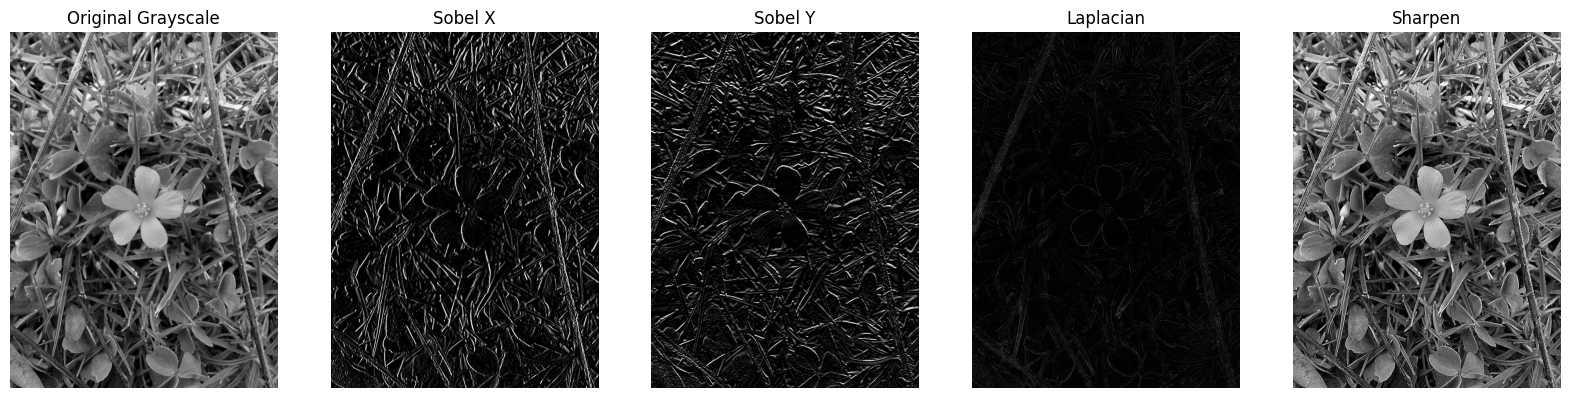

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
import numpy as np

#  Load the image and convert to grayscale
image_path = '/Users/tasnemtamer/Downloads/sky/images/garden.jpeg'
image = mpimg.imread(image_path)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

#  Define custom kernels (Sobel X, Sobel Y, Laplacian, Sharpen)
sobel_y = np.array([[ -1, -2, -1], [  0,  0,  0], [  1,  2,  1]])

sobel_x = np.array([[ -1,  0,  1],[ -2,  0,  2],  [ -1,  0,  1]])

laplacian = np.array([[  0,  1,  0],  [  1, -4,  1], [  0,  1,  0]])

sharpen = np.array([[  0, -1,  0], [ -1,  5, -1], [  0, -1,  0]])

#  Apply filters using filter2D
filtered_sobel_x = cv2.filter2D(gray, -1, sobel_x)
filtered_sobel_y = cv2.filter2D(gray, -1, sobel_y)
filtered_laplacian = cv2.filter2D(gray, -1, laplacian)
filtered_sharpen = cv2.filter2D(gray, -1, sharpen)

#  Plot results in a grid
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
titles = ['Original Grayscale', 'Sobel X', 'Sobel Y', 'Laplacian', 'Sharpen']
images_to_plot = [gray, filtered_sobel_x, filtered_sobel_y, filtered_laplacian, filtered_sharpen]

for i in range(5):
    axes[i].imshow(images_to_plot[i], cmap='gray')
    axes[i].set_title(titles[i])
    axes[i].axis('off')
    
plt.show()


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision.datasets import FashionMNIST
from torch.utils.data import DataLoader
from torchvision import transforms

# Load FashionMNIST dataset
data_transform = transforms.ToTensor()
train_data = FashionMNIST(root='./data', train=True, download=True, transform=data_transform)
batch_size = 20
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)

# Define a simple CNN class
class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()
        # 1 input channel, 10 output channels, 3x3 kernel
        self.conv1 = nn.Conv2d(1, 10, 3)
        self.pool = nn.MaxPool2d(2, 2)
        # 10 input channels, 20 output channels, 3x3 kernel
        self.conv2 = nn.Conv2d(10, 20, 3)
        self.fc1 = nn.Linear(20 * 5 * 5, 50)
        self.fc1_drop = nn.Dropout(p=0.4)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1) # Flatten
        x = F.relu(self.fc1(x))
        x = self.fc1_drop(x)
        x = F.log_softmax(self.fc2(x), dim=1)
        return x

net = SimpleNet()

#  Set up optimizer and loss function
criterion = nn.NLLLoss() # or CrossEntropyLoss
optimizer = optim.Adam(net.parameters(), lr=0.001)

#  Short training loop (3 epochs)
n_epochs = 1
for epoch in range(n_epochs):
    running_loss = 0.0
    correct = 0
    total = 0
    
    for batch_i, data in enumerate(train_loader):
        inputs, labels = data
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
        # Calculate accuracy
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    avg_loss = running_loss / len(train_loader)
    print('Epoch [{}/{}] - Avg. Loss: {:.4f} - Accuracy: {:.2f}%'.format(epoch+1, n_epochs, avg_loss, accuracy))

print('Finished Training')

Epoch [1/1] - Avg. Loss: 0.7011 - Accuracy: 73.88%
Finished Training


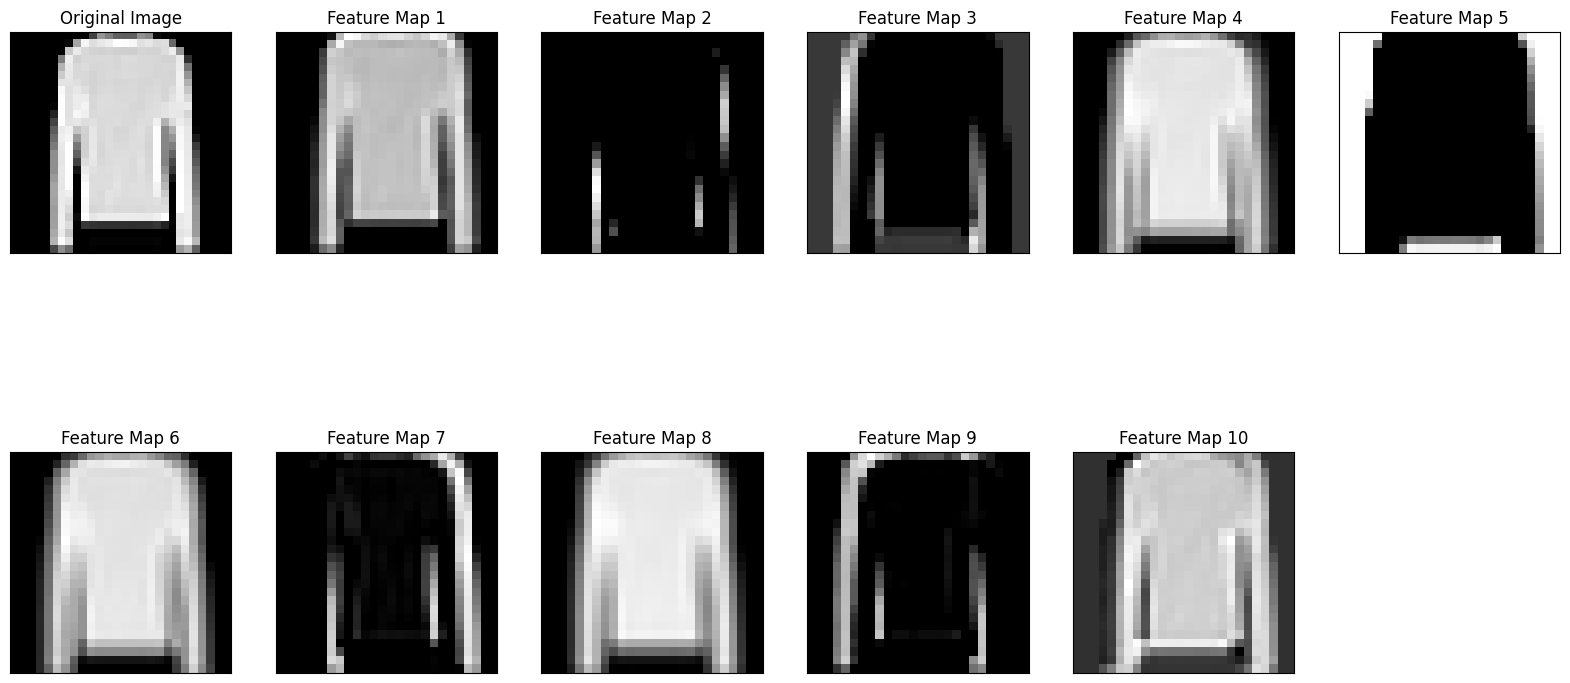

In [14]:

import numpy as np
import matplotlib.pyplot as plt

test_data = FashionMNIST(root='./data', train=False, download=True, transform=data_transform)
test_loader = DataLoader(test_data, batch_size=1, shuffle=True)
dataiter = iter(test_loader)
images, labels = next(dataiter)

# Get the original image to plot it
img = np.squeeze(images[0].numpy())

#  Forward pass through the first convolutional layer
# We just pass the image through conv1 and apply ReLU
net.eval()
with torch.no_grad():
    conv_out = net.conv1(images)
    activated_layer = F.relu(conv_out)

#  Convert feature maps to NumPy array
feature_maps = activated_layer.numpy()

#  Plot the original image and the first few feature maps
fig = plt.figure(figsize=(20, 10))

# Plot original image first
ax = fig.add_subplot(2, 6, 1, xticks=[], yticks=[])
ax.imshow(img, cmap='gray')
ax.set_title('Original Image')

# Plot the 10 feature maps from conv1
for i in range(10):
    ax = fig.add_subplot(2, 6, i+2, xticks=[], yticks=[])
    ax.imshow(np.squeeze(feature_maps[0, i]), cmap='gray')
    ax.set_title('Feature Map %s' % str(i+1))

plt.show()

In [13]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import cv2                     

image_path = '/Users/tasnemtamer/Downloads/sky/images/baby.jpg'
image = cv2.imread(image_path)

if image is None:
    print(f"Error: Could not load image at {image_path}. Check the file path.")
else:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)  
    cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
    face_cascade = cv2.CascadeClassifier(cascade_path)

    faces = face_cascade.detectMultiScale(gray, 4, 6)
    print('We found ' + str(len(faces)) + ' faces in this image')

    img_with_detections = np.copy(image)   
    for (x, y, w, h) in faces:
        cv2.rectangle(img_with_detections, (x, y), (x+w, y+h), (255, 0, 0), 5)  

    plt.figure(figsize=(12, 6))
    plt.imshow(img_with_detections)
    plt.title(f'Detected Faces: {len(faces)}')
    plt.axis('off')
    plt.show()

Error: Could not load image at /Users/tasnemtamer/Downloads/sky/images/baby.jpg. Check the file path.
